In [1]:
# PyTorch library import karta hai (deep learning models banane ke liye)
import torch

# Neural network modules import karta hai
import torch.nn as nn

# Optimization algorithms import karta hai (model training ke liye)
import torch.optim as optim

# Custom dataset aur data batches banane ke liye import karta hai
from torch.utils.data import Dataset, DataLoader

# Image preprocessing aur transformations ke liye import karta hai
from torchvision import transforms

# Images open aur process karne ke liye PIL import karta hai
from PIL import Image

# CSV aur tabular data handle karne ke liye Pandas import karta hai
import pandas as pd

# Arrays aur numerical operations ke liye NumPy import karta hai
import numpy as np

# File aur folder operations ke liye os module import karta hai
import os

# Images aur graphs display karne ke liye Matplotlib import karta hai
import matplotlib.pyplot as plt

# Installed PyTorch version print karta hai
print("PyTorch version:", torch.__version__)

# Confirm karta hai ki sabhi libraries successfully load ho gayi hain
print("All libraries loaded!")

PyTorch version: 2.12.1+cpu
All libraries loaded!


In [2]:
# Labels ko numeric values me convert karne ke liye mapping banata hai
label_map = {'good': 0, 'average': 1, 'poor': 2}

# Custom Dataset class define karta hai
class WebsiteDataset(Dataset):

    # Dataset initialize karta hai
    def __init__(self, dataframe, images_dir, transform=None):
        self.df = dataframe
        self.images_dir = images_dir
        self.transform = transform

    # Dataset me total samples ki sankhya return karta hai
    def __len__(self):
        return len(self.df)

    # Given index ke liye image aur label return karta hai
    def __getitem__(self, idx):

        # Current image ka filename leta hai
        img_name = self.df.iloc[idx]['filename']

        # Image ka complete path banata hai
        img_path = os.path.join(self.images_dir, img_name)

        # Image ko open karke RGB format me convert karta hai
        image = Image.open(img_path).convert('RGB')

        # Agar transform diya gaya ho to image par apply karta hai
        if self.transform:
            image = self.transform(image)

        # Label ko text se numeric value me convert karta hai
        label = label_map[self.df.iloc[idx]['label']]

        # Image aur label return karta hai
        return image, label

# Confirm karta hai ki Dataset class successfully define ho gayi hai
print("Dataset class defined!")

Dataset class defined!


In [3]:
# Images folder ka path define karta hai (naye local structure ke hisaab se)
IMAGES_DIR = r"C:\Projects\Internship_Learning\dataset\images"

# Labels CSV file ka path define karta hai (naye local structure ke hisaab se)
LABELS_PATH = r"C:\Projects\Internship_Learning\dataset\labels.csv"

# Labels CSV file ko DataFrame me load karta hai
df_labels = pd.read_csv(LABELS_PATH)


# train_test_split function import karta hai
from sklearn.model_selection import train_test_split

# Dataset ko train aur test set me split karta hai
# test_size=0.2 -> 20% data testing ke liye
# random_state=42 -> Har baar same split mile
# stratify -> Har class ka ratio train aur test dono me same rakhta hai
train_df, test_df = train_test_split(
    df_labels,
    test_size=0.2,
    random_state=42,
    stratify=df_labels['label']
)

# Train set ki total samples print karta hai
print("Train size:", len(train_df))

# Test set ki total samples print karta hai
print("Test size:", len(test_df))

# Image preprocessing pipeline define karta hai
transform = transforms.Compose([
    # Image ko 224x224 size me resize karta hai
    transforms.Resize((224, 224)),
    # Image ko Tensor format me convert karta hai
    transforms.ToTensor(),
    # Image ko normalize karta hai taaki model better train ho
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Training dataset create karta hai
train_dataset = WebsiteDataset(
    train_df.reset_index(drop=True),
    IMAGES_DIR,
    transform
)

# Testing dataset create karta hai
test_dataset = WebsiteDataset(
    test_df.reset_index(drop=True),
    IMAGES_DIR,
    transform
)

# Training DataLoader create karta hai
# batch_size=8 -> Ek baar me 8 images process hongi
# shuffle=True -> Har epoch me data shuffle hoga
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)

# Testing DataLoader create karta hai
# shuffle=False -> Test data ka order same rahega
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

# Confirm karta hai ki DataLoaders successfully ready hain
print("DataLoaders ready!")

Train size: 160
Test size: 40
DataLoaders ready!


In [4]:
# Simple CNN model define karta hai
class SimpleCNN(nn.Module):

    # Model initialize karta hai
    def __init__(self):
        super(SimpleCNN, self).__init__()

        # Convolution layers define karta hai
        self.conv_layers = nn.Sequential(

            # Pehla Convolution layer
            # 3 input channels (RGB), 16 output feature maps
            nn.Conv2d(3, 16, kernel_size=3, padding=1),

            # ReLU activation apply karta hai
            nn.ReLU(),

            # Feature map ka size aadha karta hai (224 -> 112)
            nn.MaxPool2d(2, 2),

            # Dusra Convolution layer
            nn.Conv2d(16, 32, kernel_size=3, padding=1),

            # ReLU activation apply karta hai
            nn.ReLU(),

            # Feature map ka size aadha karta hai (112 -> 56)
            nn.MaxPool2d(2, 2),

            # Teesra Convolution layer
            nn.Conv2d(32, 64, kernel_size=3, padding=1),

            # ReLU activation apply karta hai
            nn.ReLU(),

            # Feature map ka size aadha karta hai (56 -> 28)
            nn.MaxPool2d(2, 2)
        )

        # Fully Connected layers define karta hai
        self.fc_layers = nn.Sequential(

            # Multi-dimensional feature maps ko 1D vector me convert karta hai
            nn.Flatten(),

            # Features ko 256 neurons me map karta hai
            nn.Linear(64 * 28 * 28, 256),

            # ReLU activation apply karta hai
            nn.ReLU(),

            # Overfitting kam karne ke liye Dropout use karta hai
            nn.Dropout(0.5),

            # Final output layer (3 classes: good, average, poor)
            nn.Linear(256, 3)
        )

    # Forward pass define karta hai
    def forward(self, x):

        # Input ko convolution layers se pass karta hai
        x = self.conv_layers(x)

        # Features ko fully connected layers se pass karta hai
        x = self.fc_layers(x)

        # Final output return karta hai
        return x

# CNN model ka object banata hai
model = SimpleCNN()

# Model architecture print karta hai
print(model)

# Model ke total trainable parameters print karta hai
print("\nTotal parameters:", sum(p.numel() for p in model.parameters()))

SimpleCNN(
  (conv_layers): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=50176, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=3, bias=True)
  )
)

Total parameters: 12869667


In [5]:
# Multi-class classification ke liye loss function define karta hai
criterion = nn.CrossEntropyLoss()

# Adam optimizer define karta hai
# lr=0.001 -> Learning rate set karta hai
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Total training epochs define karta hai
EPOCHS = 10

# Har epoch ka loss store karne ke liye list banata hai
train_losses = []

# Har epoch ki accuracy store karne ke liye list banata hai
train_accuracies = []

# Training start hone ka message print karta hai
print("Training started...")
print("="*50)

# Model ko specified epochs tak train karta hai
for epoch in range(EPOCHS):

    # Model ko training mode me set karta hai
    model.train()

    # Running loss initialize karta hai
    running_loss = 0.0

    # Correct predictions count initialize karta hai
    correct = 0

    # Total samples count initialize karta hai
    total = 0

    # Training data ko batch-wise process karta hai
    for images, labels in train_loader:

        # Forward pass se predictions nikalta hai
        outputs = model(images)

        # Predicted output aur actual labels ke beech loss calculate karta hai
        loss = criterion(outputs, labels)

        # Previous gradients ko clear karta hai
        optimizer.zero_grad()

        # Backward pass se gradients calculate karta hai
        loss.backward()

        # Model ke weights update karta hai
        optimizer.step()

        # Current batch ka loss add karta hai
        running_loss += loss.item()

        # Highest score wali class ko prediction maanta hai
        _, predicted = torch.max(outputs, 1)

        # Total samples count update karta hai
        total += labels.size(0)

        # Correct predictions count update karta hai
        correct += (predicted == labels).sum().item()

    # Current epoch ka average loss calculate karta hai
    epoch_loss = round(running_loss / len(train_loader), 4)

    # Current epoch ki accuracy calculate karta hai
    epoch_acc = round(correct / total * 100, 2)

    # Epoch loss list me store karta hai
    train_losses.append(epoch_loss)

    # Epoch accuracy list me store karta hai
    train_accuracies.append(epoch_acc)

    # Current epoch ka result print karta hai
    print(f"Epoch [{epoch+1}/{EPOCHS}] Loss: {epoch_loss} | Accuracy: {epoch_acc}%")

# Training complete hone ka message print karta hai
print("="*50)
print("Training complete!")

Training started...
Epoch [1/10] Loss: 1.556 | Accuracy: 38.75%
Epoch [2/10] Loss: 0.9896 | Accuracy: 53.75%
Epoch [3/10] Loss: 0.8639 | Accuracy: 60.0%
Epoch [4/10] Loss: 0.6186 | Accuracy: 73.75%
Epoch [5/10] Loss: 0.4476 | Accuracy: 79.38%
Epoch [6/10] Loss: 0.3112 | Accuracy: 88.12%
Epoch [7/10] Loss: 0.1927 | Accuracy: 95.0%
Epoch [8/10] Loss: 0.0843 | Accuracy: 96.88%
Epoch [9/10] Loss: 0.0656 | Accuracy: 98.12%
Epoch [10/10] Loss: 0.061 | Accuracy: 96.88%
Training complete!


In [6]:
# Model ko evaluation mode me set karta hai
model.eval()

# Correct predictions count initialize karta hai
correct = 0

# Total test samples count initialize karta hai
total = 0

# Sabhi predicted labels store karne ke liye list banata hai
all_preds = []

# Sabhi actual labels store karne ke liye list banata hai
all_labels = []

# Evaluation ke dauran gradient calculation disable karta hai
# Isse memory kam use hoti hai aur evaluation fast hota hai
with torch.no_grad():

    # Test data ko batch-wise process karta hai
    for images, labels in test_loader:

        # Model se predictions nikalta hai
        outputs = model(images)

        # Highest score wali class ko prediction maanta hai
        _, predicted = torch.max(outputs, 1)

        # Total samples count update karta hai
        total += labels.size(0)

        # Correct predictions count update karta hai
        correct += (predicted == labels).sum().item()

        # Predicted labels list me add karta hai
        all_preds.extend(predicted.numpy())

        # Actual labels list me add karta hai
        all_labels.extend(labels.numpy())

# Test accuracy calculate karta hai
test_accuracy = round(correct / total * 100, 2)

# Test accuracy print karta hai
print("Test Accuracy:", test_accuracy, "%")

# Classification Report function import karta hai
from sklearn.metrics import classification_report

# Numeric labels ke corresponding class names define karta hai
label_names = ['good', 'average', 'poor']

# Classification Report ki heading print karta hai
print("\nClassification Report:")

# Precision, Recall aur F1-score report print karta hai
print(classification_report(all_labels, all_preds, target_names=label_names))

Test Accuracy: 52.5 %

Classification Report:
              precision    recall  f1-score   support

        good       0.62      0.67      0.64        12
     average       0.50      0.44      0.47        16
        poor       0.46      0.50      0.48        12

    accuracy                           0.53        40
   macro avg       0.53      0.53      0.53        40
weighted avg       0.52      0.53      0.52        40



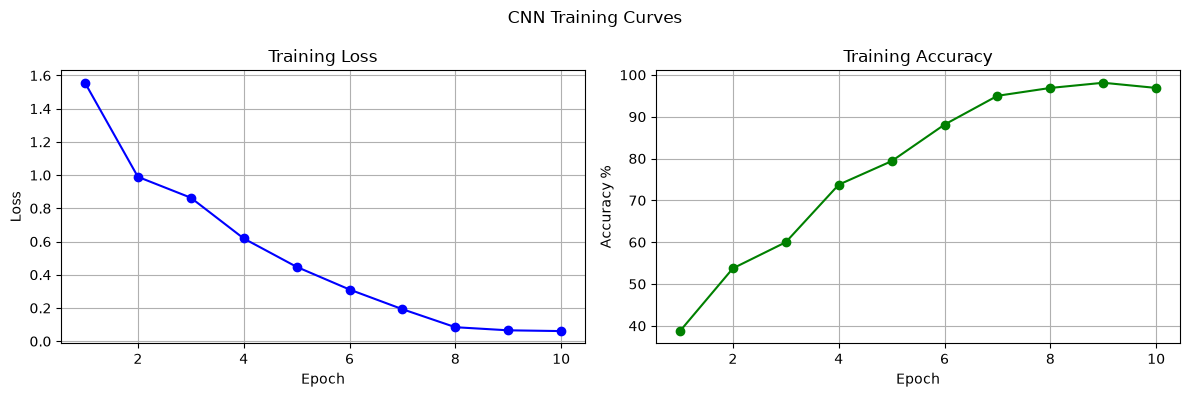


Observation: Training accuracy reached 96.88%
Test accuracy was 52.5%
Gap: 44.38 percentage points
This gap suggests overfitting — model memorizing train data rather than generalizing.


In [7]:
# Training loss aur accuracy graph plot karne ke liye figure create karta hai
plt.figure(figsize=(12, 4))

# Pehla subplot create karta hai
plt.subplot(1, 2, 1)

# Har epoch ka training loss plot karta hai
plt.plot(range(1, EPOCHS+1), train_losses, 'b-o')

# Graph ka title set karta hai
plt.title('Training Loss')

# X-axis ka label set karta hai
plt.xlabel('Epoch')

# Y-axis ka label set karta hai
plt.ylabel('Loss')

# Grid display karta hai
plt.grid(True)

# Dusra subplot create karta hai
plt.subplot(1, 2, 2)

# Har epoch ki training accuracy plot karta hai
plt.plot(range(1, EPOCHS+1), train_accuracies, 'g-o')

# Graph ka title set karta hai
plt.title('Training Accuracy')

# X-axis ka label set karta hai
plt.xlabel('Epoch')

# Y-axis ka label set karta hai
plt.ylabel('Accuracy %')

# Grid display karta hai
plt.grid(True)

# Puri figure ka main title set karta hai
plt.suptitle('CNN Training Curves', fontsize=12)

# Layout automatically adjust karta hai
plt.tight_layout()

# Graph display karta hai
plt.show()

# Final train aur test accuracy ka gap dynamically calculate karta hai
final_train_acc = train_accuracies[-1]
train_test_gap = round(final_train_acc - test_accuracy, 2)

# Training aur testing results ka observation print karta hai (naye run ke actual numbers ke saath)
print(f"\nObservation: Training accuracy reached {final_train_acc}%")
print(f"Test accuracy was {test_accuracy}%")
print(f"Gap: {train_test_gap} percentage points")

# Overfitting check dynamically karta hai (agar gap zyada hai to overfitting flag karta hai)
if train_test_gap > 20:
    print("This gap suggests overfitting — model memorizing train data rather than generalizing.")
else:
    print("Train/test gap is reasonable — no strong overfitting signal.")